Machine status as a uniform (and Bernoulli) RV (Victor Z and David Cole, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $X$, $x_\omega$ | `x_omega` | weekly status: $0$ = fails, $1$ = works |
| $S$ | `S` | number of weeks observed (156) |
| $a$, $b$, $n$ | `a`, `b`, `n` | uniform parameters, $n=b-a+1$ |
| $\hat{\mathbb{P}}(X=x)$ | `P_hat[x]` | empirical pdf |

## Machine status as a uniform RV

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Three years of weekly records ($S=156$) in which the machine failed in 79 weeks.

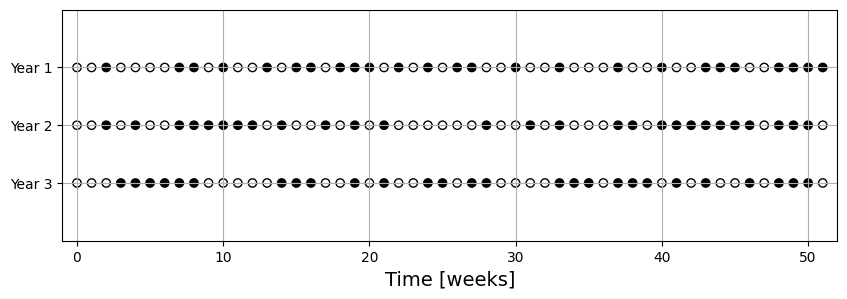

In [2]:
np.random.seed(0)  # reproducibility
S = 156
n_fail = 79
x_omega = np.ones(S, dtype=int)                                   # 1 = works
x_omega[np.random.choice(S, n_fail, replace=False)] = 0           # 0 = fails

weeks = np.arange(52)
plt.figure(figsize=(10, 3))
for year in range(3):
    status = x_omega[52*year:52*(year+1)]
    plt.scatter(weeks, np.full(52, 3 - year), c=np.where(status == 0, 'black', 'white'), edgecolors='black')
plt.yticks([1, 2, 3], ['Year 3', 'Year 2', 'Year 1'])
plt.xlabel('Time [weeks]', fontsize=14)
plt.grid(True)
plt.axis([-1, 52, 0, 4])
plt.show()

Uniform model with $\mathcal{D}=\{0,1\}$: $a=0$, $b=1$, $n=2$, so $\mathbb{P}(X=x)=1/n=1/2$.
Compare with the empirical pdf $\hat{\mathbb{P}}(X=x)=\frac{1}{S}\sum_{\omega}\mathbf{1}[x_\omega=x]$.

In [3]:
a, b = 0, 1
n = b - a + 1
P_hat = {x: np.mean(x_omega == x) for x in (0, 1)}
print(f"Uniform model: P(X=0) = P(X=1) = 1/n = {1/n}")
print(f"Empirical:     P_hat(X=0) = {P_hat[0]:.4f},  P_hat(X=1) = {P_hat[1]:.4f}")

Uniform model: P(X=0) = P(X=1) = 1/n = 0.5
Empirical:     P_hat(X=0) = 0.5064,  P_hat(X=1) = 0.4936


## Machine status as a Bernoulli RV

For a Bernoulli RV $X\sim\mathcal{B}(p)$, $\mathbb{E}_X=p$, so the empirical mean
$\hat{\mathbb{E}}_X$ estimates $p$; here $X=1$ means the machine works.

In [4]:
p_hat = np.mean(x_omega)                  # E_hat[X] = p_hat
print(f"p_hat = {p_hat:.4f}  ->  X ~ B({p_hat:.2f})")
print(f"E_X = p = {p_hat:.4f},  V_X = p(1-p) = {p_hat*(1-p_hat):.4f}")

p_hat = 0.4936  ->  X ~ B(0.49)
E_X = p = 0.4936,  V_X = p(1-p) = 0.2500
